# Piste 5 — Estimer la valeur de revente des camions d'occasion (régression)

**Question métier :** combien vaut ce camion d'occasion ? Un prix de reprise juste et rapide aide le commercial comme le client.

> ⚠️ **Données simulées** : la formule de prix est inventée pour démontrer la méthode. Avec l'historique réel des ventes d'occasion, le résultat serait à vérifier.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# ---------- DONNÉES SIMULÉES (pour démontrer la méthode) ----------
rng = np.random.default_rng(7)
n = 3000
prix_neuf = {"XB": 85000, "XD": 110000, "XF": 135000, "XG": 150000}
usure = {"Livraison urbaine": 0.04, "Distribution régionale": 0.0,
         "Longue distance": -0.02, "Chantier / BTP": 0.10}   # pénalité selon l'usage

df = pd.DataFrame({
    "modele": rng.choice(list(prix_neuf), n, p=[0.2, 0.35, 0.3, 0.15]),
    "usage": rng.choice(list(usure), n),
    "age_ans": rng.uniform(1, 10, n).round(1),
    "entretien_reseau": rng.choice([1, 0], n, p=[0.7, 0.3]),   # entretenu chez DAF ?
})
km_par_an = df["usage"].map({"Livraison urbaine": 35000, "Distribution régionale": 70000,
                             "Longue distance": 140000, "Chantier / BTP": 25000})
df["kilometrage"] = (df["age_ans"] * km_par_an * rng.uniform(0.7, 1.3, n)).round(-3)

prix = (df["modele"].map(prix_neuf)
        * np.exp(-0.11 * df["age_ans"])                 # décote avec l'âge
        * (1 - 0.00000045 * df["kilometrage"])           # décote avec les kilomètres
        * (1 - df["usage"].map(usure))
        * (1 + 0.06 * df["entretien_reseau"])            # bonus entretien suivi
        * rng.normal(1, 0.06, n))                        # bruit du marché
df["prix_revente"] = prix.clip(lower=8000).round(-2)
print(df.shape); df.head()

(3000, 6)


,modele,usage,age_ans,entretien_reseau,kilometrage,prix_revente
0,XF,Longue distance,6.7,1,699000.0,50600.0
1,XG,Livraison urbaine,6.1,1,225000.0,66800.0
2,XF,Distribution régionale,6.6,1,578000.0,55800.0
3,XD,Chantier / BTP,4.8,0,122000.0,53300.0
4,XD,Livraison urbaine,9.0,0,221000.0,37400.0


## Deux modèles comparés
One-hot encoding pour les catégories sans ordre, standardisation pour les nombres, le tout dans un Pipeline.

Régression linéaire  MAE =   5 163 €  |  RMSE =   6 665 €  |  R² = 0.931


Random Forest        MAE =   3 310 €  |  RMSE =   4 653 €  |  R² = 0.966


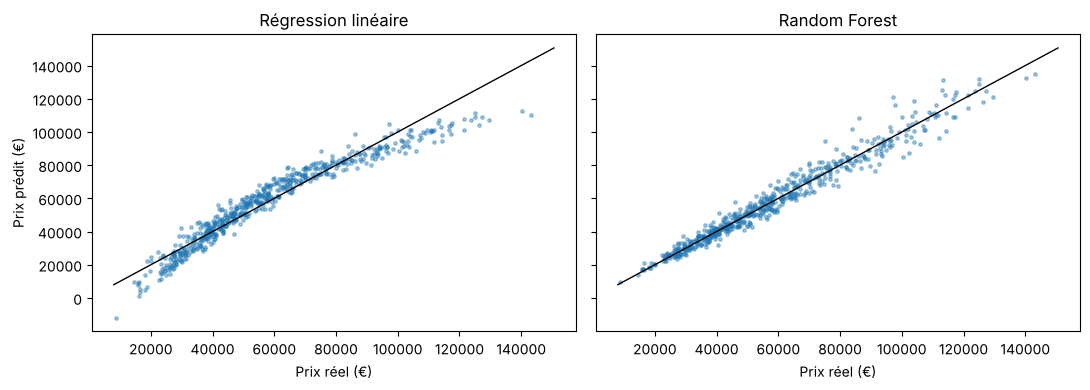

In [2]:
X = df.drop(columns="prix_revente"); y = df["prix_revente"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

prep = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), ["modele", "usage"]),   # catégories sans ordre
    ("num", StandardScaler(), ["age_ans", "kilometrage", "entretien_reseau"]),
])
modeles = {
    "Régression linéaire": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1),
}
preds = {}
for nom, m in modeles.items():
    pipe = Pipeline([("prep", prep), ("modele", m)]).fit(X_train, y_train)
    p = pipe.predict(X_test); preds[nom] = p
    print(f"{nom:20s} MAE = {mean_absolute_error(y_test, p):7,.0f} €  |  "
          f"RMSE = {mean_squared_error(y_test, p) ** 0.5:7,.0f} €  |  R² = {r2_score(y_test, p):.3f}".replace(",", " "))

fig, ax = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for a, (nom, p) in zip(ax, preds.items()):
    a.scatter(y_test, p, s=6, alpha=0.4)
    a.plot([y.min(), y.max()], [y.min(), y.max()], color="black", linewidth=1)
    a.set_title(nom); a.set_xlabel("Prix réel (€)")
ax[0].set_ylabel("Prix prédit (€)")
plt.tight_layout(); plt.savefig("images/occasion_predit_vs_reel.png", dpi=150); plt.show()

## Conclusions
- Le Random Forest se trompe d'environ **3 300 €** en moyenne, contre environ 5 200 € pour la régression linéaire (environ 36 % d'erreur en moins).
- La régression linéaire dessine une courbe : elle sous-estime les camions chers et peut prédire un **prix négatif** pour les moins chers. La décote n'étant pas proportionnelle, un modèle non linéaire est plus adapté.